In [25]:
# Installing dependecies
!sudo apt install tesseract-ocr -y


!pip install pytesseract google-generativeai pydantic opencv-python-headless -q

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [26]:
import cv2
import pytesseract
import google.generativeai as genai
from google.colab import drive
from pydantic import BaseModel, Field
import json
import numpy as np
from IPython.display import display
from PIL import Image
import os


drive.mount('/content/drive')



api_key = "AQ.Ab8RN6J2J8d-Lib6xj_DBrzTC-kubFSm1DPqvtCLaktsEO0vDA"
genai.configure(api_key=api_key)
print("gemini API Key configured successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
gemini API Key configured successfully!


In [27]:
# image preprocessing code

def extract_text_from_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Could not read image at {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


    inverted = cv2.bitwise_not(gray)

    thresh = cv2.threshold(inverted, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

    custom_config = r'--oem 3 --psm 4'

    raw_text = pytesseract.image_to_string(thresh, config=custom_config)

    return raw_text.strip()

In [28]:
# 1. Define the exact data structure including location fields
class RelationshipData(BaseModel):
    subject: str = Field(description="The primary person being discussed (e.g., Veena Nayar)")
    related_person: str = Field(description="The person related to the subject, if any. Use 'None' if NA.")
    relationship_type: str = Field(description="How they are related (e.g., Daughter, Son, Daughter-in-law, Grandchild)")
    event: str = Field(description="The main event mentioned (e.g., Death, Chautha & Uthala)")
    event_date: str = Field(description="Date of the event. Return 'Unknown' if not found.")
    event_venue: str = Field(description="The name of the building or venue. Return 'Unknown' if not found.")
    event_address: str = Field(description="The street address and city for the event. Return 'Unknown' if not found.")

def extract_structured_data(ocr_text):
    # Using the current 3.8 Flash model
    model = genai.GenerativeModel('gemini-3.8-flash')

    prompt = f"""
    You are an expert information extraction system.
    Read the following OCR text from a newspaper clipping.
    Extract all listed family members and their exact relationship to the deceased.
    Also, extract the venue name and the full address where the scheduled event is taking place.
    Fix any obvious OCR typos in the text during your reasoning.

    OCR TEXT:
    "{ocr_text}"
    """

    response = model.generate_content(
        prompt,
        generation_config=genai.GenerationConfig(
            response_mime_type="application/json",
            response_schema=list[RelationshipData],
        ),
    )

    return json.loads(response.text)

print("✅ LLM Extraction function defined!")

✅ LLM Extraction function defined!



 Processing: /content/drive/MyDrive/Web3/Photo from Rohit



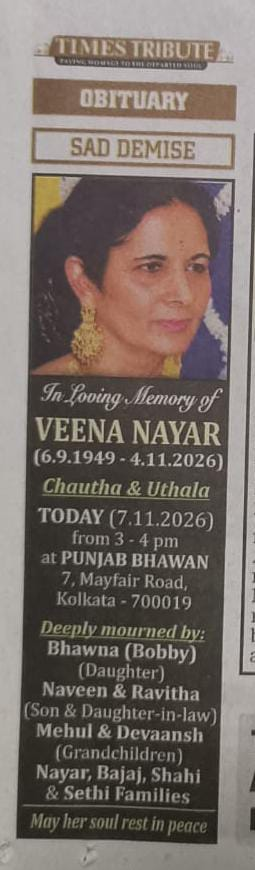

Raw OCR Text Extracted:

a fouing Memory, wf
VEENA NAYAR

{6.9.1949- 4,11.2026}
Chautha & Uthata
TODAY (7.11.2026)
trom 3 - 4 pm
al PUNJAB BHAWAN
7, Mayfair Road,
Kolkata - 700019
Decply mourned b
Bhawna (Bobby)
{Daughter}
Naveen & Ravitha

(Son & Daughtor-in-law)
Mebul & [ Devaansh

etn Meg vate

 Running LLM Reasoning & Extraction...

 Final Extracted Information (JSON):
[
    {
        "event": "Chautha & Uthala",
        "event_address": "7, Mayfair Road, Kolkata - 700019",
        "event_date": "7.11.2026",
        "event_venue": "PUNJAB BHAWAN",
        "related_person": "Bhawna (Bobby)",
        "relationship_type": "Daughter",
        "subject": "Veena Nayar"
    },
    {
        "event": "Chautha & Uthala",
        "event_address": "7, Mayfair Road, Kolkata - 700019",
        "event_date": "7.11.2026",
        "event_venue": "PUNJAB BHAWAN",
        "related_person": "Naveen",
        "relationship_type": "Son",
        "subject": "Veena Nayar"
    },
    {
        "event": "C

In [29]:

IMAGE_PATH = '/content/drive/MyDrive/Web3/Photo from Rohit'

if not os.path.exists(IMAGE_PATH):
    print(f" File not found at {IMAGE_PATH}. Please check the path and try again.")
else:
    print(f"\n Processing: {IMAGE_PATH}\n")


    display(Image.open(IMAGE_PATH))



    raw_text = extract_text_from_image(IMAGE_PATH)
    print("Raw OCR Text Extracted:\n")

    print(raw_text if raw_text else "[No text detected]")



    if raw_text:
        print("\n Running LLM Reasoning & Extraction...")
        structured_data = extract_structured_data(raw_text)

        print("\n Final Extracted Information (JSON):")
        print(json.dumps(structured_data, indent=4))
    else:
        print(" No text could be extracted from the image. Try a clearer photo.")

In [30]:
import google.generativeai as genai
from pydantic import BaseModel, Field
import json
from PIL import Image

# 1. Define the updated exact data structure
class RelationshipData(BaseModel):
    subject: str = Field(description="The primary person being discussed (e.g., Veena Nayar)")
    related_person: str = Field(description="The person related to the subject, if any.")
    relationship_type: str = Field(description="How they are related (e.g., Daughter, Son, Daughter-in-law, Grandchild)")
    event: str = Field(description="The main event mentioned (e.g., Death, Chautha & Uthala)")
    event_date: str = Field(description="Date of the event. Return 'Unknown' if not found.")
    event_venue: str = Field(description="The name of the building or venue (e.g., Punjab Bhawan). Return 'Unknown' if not found.")
    event_address: str = Field(description="The street address and city for the event. Return 'Unknown' if not found.")

def process_image_directly(image_path):
    model = genai.GenerativeModel('gemini-3.8-flash')

    img = Image.open(image_path)

    # 2. Update the prompt to explicitly ask for the location
    prompt = """
    You are an expert information extraction system.
    Read this newspaper clipping carefully. Extract all listed family members and their exact relationship to the deceased.
    Also, extract the venue name and the full address where the scheduled event is taking place.
    Ensure you capture names accurately (e.g., Bobby, Naveen, Ravitha, Mehul, Devaansh).
    """

    response = model.generate_content(
        [prompt, img],
        generation_config=genai.GenerationConfig(
            response_mime_type="application/json",
            response_schema=list[RelationshipData],
        ),
    )

    return json.loads(response.text)

# --- Execute ---
IMAGE_PATH = '/content/drive/MyDrive/Web3/Photo from Rohit'
extracted_data = process_image_directly(IMAGE_PATH)

print("\n✅ Final Extracted Information (JSON):")
print(json.dumps(extracted_data, indent=4))


✅ Final Extracted Information (JSON):
[
    {
        "event": "Chautha & Uthala",
        "event_address": "7, Mayfair Road, Kolkata - 700019",
        "event_date": "7.11.2026",
        "event_venue": "Punjab Bhawan",
        "related_person": "Bhawna (Bobby)",
        "relationship_type": "Daughter",
        "subject": "Veena Nayar"
    },
    {
        "event": "Chautha & Uthala",
        "event_address": "7, Mayfair Road, Kolkata - 700019",
        "event_date": "7.11.2026",
        "event_venue": "Punjab Bhawan",
        "related_person": "Naveen",
        "relationship_type": "Son",
        "subject": "Veena Nayar"
    },
    {
        "event": "Chautha & Uthala",
        "event_address": "7, Mayfair Road, Kolkata - 700019",
        "event_date": "7.11.2026",
        "event_venue": "Punjab Bhawan",
        "related_person": "Ravitha",
        "relationship_type": "Daughter-in-law",
        "subject": "Veena Nayar"
    },
    {
        "event": "Chautha & Uthala",
        "event